In [2]:
# STEP 1: DEFINE INVENTORY SENSITIVITY FRAMEWORK

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: LOCATE EXISTING PROJECT OUTPUTS
# ------------------------------------------------------------

project_root = Path.cwd()
processed_dir = project_root / "data" / "processed"

forecast_path = (
    processed_dir / "forecast_lead_time_baseline_2019.csv"
)

scenarios_path = (
    processed_dir / "inventory_scenario_definitions.csv"
)

readiness_path = (
    processed_dir / "inventory_launch_readiness.csv"
)

required_files = [
    forecast_path,
    scenarios_path,
    readiness_path
]

for path in required_files:
    assert path.is_file(), (
        f"Required file missing: {path.name}"
    )

print("===== SENSITIVITY INPUT FILES =====")

for path in required_files:
    print("Found:", path.name)


# ------------------------------------------------------------
# PART 2: LOAD FORECAST AND INVENTORY DATA
# ------------------------------------------------------------

forecast_df = pd.read_csv(
    forecast_path,
    parse_dates=[
        "Forecast_Origin",
        "Forecast_Week"
    ]
)

scenario_definitions = pd.read_csv(
    scenarios_path
)

launch_readiness = pd.read_csv(
    readiness_path
)

forecast_df = (
    forecast_df
    .sort_values("Lead_Time_Weeks")
    .reset_index(drop=True)
)

print("\n===== INPUT DATASET SIZES =====")

print("Forecast weeks:", len(forecast_df))
print("Original scenarios:", len(scenario_definitions))
print("Interventions:", len(launch_readiness))


# ------------------------------------------------------------
# PART 3: VALIDATE HISTORICAL FORECAST BASELINE
# ------------------------------------------------------------

assert len(forecast_df) == 4

assert forecast_df["Lead_Time_Weeks"].tolist() == [
    1, 2, 3, 4
]

assert (
    forecast_df["Forecast_Weekly_Units"] >= 0
).all()

assert np.allclose(
    forecast_df["Cumulative_Forecast_Units"],
    forecast_df["Forecast_Weekly_Units"].cumsum()
)

baseline_weekly_demand = (
    forecast_df["Forecast_Weekly_Units"]
    .to_numpy(dtype=float)
)

print("\n===== HISTORICAL FORECAST BASELINE =====")

print(
    "Forecast origin:",
    forecast_df["Forecast_Origin"].iloc[0].date()
)

print(
    "Baseline weekly demand:",
    baseline_weekly_demand.tolist()
)

print(
    "Cumulative four-week demand:",
    baseline_weekly_demand.sum()
)


# ------------------------------------------------------------
# PART 4: IDENTIFY RISK SCENARIOS
# ------------------------------------------------------------

risk_scenario_names = [
    "Demand Surge",
    "Supplier Delay"
]

risk_scenarios = (
    scenario_definitions[
        scenario_definitions["Scenario"].isin(
            risk_scenario_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(risk_scenarios) == 2

print("\n===== REFERENCE RISK SCENARIOS =====")

display(risk_scenarios)


# ------------------------------------------------------------
# PART 5: RECOVER ORIGINAL REPLENISHMENT ACTIONS
# ------------------------------------------------------------

required_action_columns = [
    "Scenario",
    "Action",
    "Extra_Units",
    "Extra_Arrival_Week",
    "Reschedule_Week"
]

assert set(required_action_columns).issubset(
    launch_readiness.columns
)

sensitivity_actions = (
    launch_readiness[
        required_action_columns
    ]
    .drop_duplicates()
    .copy()
    .reset_index(drop=True)
)

assert len(sensitivity_actions) == 7

assert not sensitivity_actions[
    ["Scenario", "Action"]
].duplicated().any()

print("\n===== REPLENISHMENT ACTIONS TO TEST =====")

display(sensitivity_actions)


# ------------------------------------------------------------
# PART 6: DEFINE SENSITIVITY PARAMETERS
# ------------------------------------------------------------

# Demand changes are relative to each scenario's
# existing demand multiplier.
#
# For example, Demand Surge already has a 1.25x
# multiplier. An additional 1.15x test means
# 1.25 * 1.15 times the original forecast.

sensitivity_parameters = {
    "Demand_Adjustment": [
        0.85,
        1.00,
        1.15
    ],

    "Starting_Inventory": [
        1100,
        1400,
        1700
    ],

    "Arrival_Week_Adjustment": [
        -1,
        0,
        1
    ],

    "Shortage_Penalty_USD": [
        25.0,
        75.0,
        125.0
    ]
}

print("\n===== SENSITIVITY PARAMETER RANGES =====")

parameter_summary = pd.DataFrame([
    {
        "Variable": name,
        "Values": str(values),
        "Options": len(values)
    }
    for name, values in sensitivity_parameters.items()
])

display(parameter_summary)


# ------------------------------------------------------------
# PART 7: CALCULATE EXPERIMENT SIZE
# ------------------------------------------------------------

cases_per_scenario = int(
    np.prod([
        len(values)
        for values in sensitivity_parameters.values()
    ])
)

total_operating_cases = (
    len(risk_scenarios) * cases_per_scenario
)

total_intervention_evaluations = (
    len(sensitivity_actions) * cases_per_scenario
)

print("\n===== SENSITIVITY EXPERIMENT DESIGN =====")

print("Cases per risk scenario:", cases_per_scenario)

print("Total operating cases:", total_operating_cases)

print(
    "Total intervention evaluations:",
    total_intervention_evaluations
)


# ------------------------------------------------------------
# PART 8: VALIDATE EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

assert cases_per_scenario == 81

assert total_operating_cases == 162

assert total_intervention_evaluations == 567

assert (
    risk_scenarios["Starting_Inventory"] >= 0
).all()

assert (
    risk_scenarios["Inbound_Units"] >= 0
).all()

assert (
    sensitivity_actions[
        ["Extra_Units", "Extra_Arrival_Week",
         "Reschedule_Week"]
    ] >= 0
).all().all()

# Even the earliest adjusted original shipment
# must occur in a valid planning week.
assert (
    risk_scenarios["Inbound_Week"].min()
    + min(sensitivity_parameters[
        "Arrival_Week_Adjustment"
    ])
) >= 1

print("\n===== FRAMEWORK VALIDATION =====")

print("Forecast input validation: PASS")
print("Two reference risk scenarios: PASS")
print("Seven original interventions: PASS")
print("81 cases per scenario: PASS")
print("567 intervention evaluations configured: PASS")

print("\n===== STEP 1 COMPLETE =====")


===== SENSITIVITY INPUT FILES =====
Found: forecast_lead_time_baseline_2019.csv
Found: inventory_scenario_definitions.csv
Found: inventory_launch_readiness.csv

===== INPUT DATASET SIZES =====
Forecast weeks: 4
Original scenarios: 3
Interventions: 7

===== HISTORICAL FORECAST BASELINE =====
Forecast origin: 2019-12-29
Baseline weekly demand: [515.0, 515.0, 515.0, 515.0]
Cumulative four-week demand: 2060.0

===== REFERENCE RISK SCENARIOS =====


,Scenario,Demand_Multiplier,Starting_Inventory,Inbound_Units,Inbound_Week
0,Demand Surge,1.25,1400,900,3
1,Supplier Delay,1.00,1400,900,5



===== REPLENISHMENT ACTIONS TO TEST =====


,Scenario,Action,Extra_Units,Extra_Arrival_Week,Reschedule_Week
0,Demand Surge,No Intervention,0,0,0
1,Demand Surge,Add 276 Units - Week 4,276,4,0
2,Demand Surge,Add 276 Units - Week 5,276,5,0
3,Supplier Delay,No Intervention,0,0,0
4,Supplier Delay,Bridge 660 Units - Week 3,660,3,0
5,Supplier Delay,Bridge 660 Units - Week 4,660,4,0
6,Supplier Delay,Expedite Original 900 - Week 3,0,0,3



===== SENSITIVITY PARAMETER RANGES =====


,Variable,Values,Options
0,Demand_Adjustment,"[0.85, 1.0, 1.15]",3
1,Starting_Inventory,"[1100, 1400, 1700]",3
2,Arrival_Week_Adjustment,"[-1, 0, 1]",3
3,Shortage_Penalty_USD,"[25.0, 75.0, 125.0]",3



===== SENSITIVITY EXPERIMENT DESIGN =====
Cases per risk scenario: 81
Total operating cases: 162
Total intervention evaluations: 567

===== FRAMEWORK VALIDATION =====
Forecast input validation: PASS
Two reference risk scenarios: PASS
Seven original interventions: PASS
81 cases per scenario: PASS
567 intervention evaluations configured: PASS

===== STEP 1 COMPLETE =====


In [3]:
# STEP 2: EXECUTE INVENTORY SENSITIVITY SIMULATIONS

from itertools import product
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: LOAD ECONOMIC ASSUMPTIONS FROM NOTEBOOK 08
# ------------------------------------------------------------

assumptions_path = (
    processed_dir / "inventory_decision_assumptions.csv"
)

assert assumptions_path.is_file()

assumptions_df = pd.read_csv(assumptions_path)

assumptions = dict(
    zip(
        assumptions_df["Parameter"],
        assumptions_df["Value"]
    )
)

emergency_premium = float(
    assumptions["Emergency supply premium"]
)

emergency_delivery_fee = float(
    assumptions["Emergency delivery fee"]
)

original_expedite_fee = float(
    assumptions["Original shipment expedite fee"]
)

launch_fill_target = float(
    assumptions["Launch fill target"]
)

watch_threshold = float(
    assumptions["Watch threshold"]
)

planning_weeks = len(forecast_df)

print("===== ECONOMIC MODEL CONFIGURATION =====")

print("Emergency premium:", emergency_premium)
print("Emergency delivery fee:", emergency_delivery_fee)
print("Original expedite fee:", original_expedite_fee)
print("Planning weeks:", planning_weeks)


# ------------------------------------------------------------
# PART 2: DEFINE REUSABLE INVENTORY SIMULATOR
# ------------------------------------------------------------

def run_sensitivity_simulation(
    scenario,
    action,
    case_id,
    starting_inventory,
    demand_adjustment,
    arrival_adjustment,
    shortage_penalty
):

    inventory = int(starting_inventory)

    original_units = int(scenario.Inbound_Units)

    # If expedited, use the intervention arrival week.
    # Otherwise use the scenario's original arrival week.
    if int(action.Reschedule_Week) > 0:

        base_original_week = int(
            action.Reschedule_Week
        )

    else:

        base_original_week = int(
            scenario.Inbound_Week
        )

    # Apply delivery-timing uncertainty to the
    # effective arrival of the original shipment.
    original_arrival_week = (
        base_original_week + int(arrival_adjustment)
    )

    assert original_arrival_week >= 1

    extra_units = int(action.Extra_Units)
    extra_arrival_week = int(
        action.Extra_Arrival_Week
    )

    # Demand adjustment applies on top of the
    # scenario's original demand multiplier.
    demand_multiplier = (
        float(scenario.Demand_Multiplier)
        * float(demand_adjustment)
    )

    weekly_records = []

    # --------------------------------------------------------
    # PART 3: SIMULATE FOUR INVENTORY WEEKS
    # --------------------------------------------------------

    for week in forecast_df.itertuples(index=False):

        week_number = int(week.Lead_Time_Weeks)

        beginning = inventory

        original_receipts = (
            original_units
            if week_number == original_arrival_week
            else 0
        )

        extra_receipts = (
            extra_units
            if (
                extra_units > 0
                and week_number == extra_arrival_week
            )
            else 0
        )

        available = (
            beginning
            + original_receipts
            + extra_receipts
        )

        demand = int(
            np.ceil(
                float(week.Forecast_Weekly_Units)
                * demand_multiplier
            )
        )

        fulfilled = min(
            available,
            demand
        )

        shortage = demand - fulfilled

        ending = available - fulfilled

        weekly_records.append({
            "Case_ID": case_id,
            "Scenario": scenario.Scenario,
            "Action": action.Action,
            "Week": week_number,
            "Forecast_Week": week.Forecast_Week,
            "Beginning_Inventory": beginning,
            "Original_Receipts": original_receipts,
            "Extra_Receipts": extra_receipts,
            "Demand_Units": demand,
            "Fulfilled_Units": fulfilled,
            "Shortage_Units": shortage,
            "Ending_Inventory": ending
        })

        inventory = ending

    weekly_df = pd.DataFrame(weekly_records)


    # --------------------------------------------------------
    # PART 4: CALCULATE SERVICE PERFORMANCE
    # --------------------------------------------------------

    total_demand = int(
        weekly_df["Demand_Units"].sum()
    )

    total_fulfilled = int(
        weekly_df["Fulfilled_Units"].sum()
    )

    total_shortage = int(
        weekly_df["Shortage_Units"].sum()
    )

    shortage_weeks = int(
        (weekly_df["Shortage_Units"] > 0).sum()
    )

    fill_rate = (
        total_fulfilled / total_demand * 100
        if total_demand > 0
        else 100.0
    )

    if (
        fill_rate >= launch_fill_target
        and shortage_weeks == 0
    ):

        readiness = "READY"

    elif fill_rate >= watch_threshold:

        readiness = "WATCH"

    else:

        readiness = "AT RISK"


    # --------------------------------------------------------
    # PART 5: CALCULATE FUTURE SUPPLY OBLIGATIONS
    # --------------------------------------------------------

    outstanding_original = (
        original_units
        if original_arrival_week > planning_weeks
        else 0
    )

    outstanding_extra = (
        extra_units
        if (
            extra_units > 0
            and extra_arrival_week > planning_weeks
        )
        else 0
    )

    total_outstanding = (
        outstanding_original
        + outstanding_extra
    )


    # --------------------------------------------------------
    # PART 6: CALCULATE ECONOMIC EXPOSURE
    # --------------------------------------------------------

    received_extra_units = int(
        weekly_df["Extra_Receipts"].sum()
    )

    shortage_exposure = (
        total_shortage * shortage_penalty
    )

    emergency_cost = (
        received_extra_units * emergency_premium
    )

    delivery_cost = (
        emergency_delivery_fee
        if received_extra_units > 0
        else 0.0
    )

    expedite_cost = (
        original_expedite_fee
        if int(action.Reschedule_Week) > 0
        else 0.0
    )

    total_exposure = (
        shortage_exposure
        + emergency_cost
        + delivery_cost
        + expedite_cost
    )


    # --------------------------------------------------------
    # PART 7: RETURN EVALUATION RESULTS
    # --------------------------------------------------------

    summary = {
        "Case_ID": case_id,
        "Scenario": scenario.Scenario,
        "Action": action.Action,
        "Demand_Adjustment": demand_adjustment,
        "Starting_Inventory": starting_inventory,
        "Arrival_Week_Adjustment": arrival_adjustment,
        "Shortage_Penalty_USD": shortage_penalty,
        "Effective_Original_Arrival_Week":
            original_arrival_week,
        "Total_Demand": total_demand,
        "Total_Fulfilled": total_fulfilled,
        "Total_Shortage": total_shortage,
        "Shortage_Weeks": shortage_weeks,
        "Fill_Rate_Pct": fill_rate,
        "Readiness_Status": readiness,
        "Received_Extra_Units": received_extra_units,
        "Outstanding_Units": total_outstanding,
        "Ending_Inventory": int(inventory),
        "Shortage_Exposure_USD": shortage_exposure,
        "Emergency_Cost_USD": emergency_cost,
        "Delivery_Cost_USD": delivery_cost,
        "Expedite_Cost_USD": expedite_cost,
        "Total_Exposure_USD": total_exposure
    }

    return summary, weekly_df


# ------------------------------------------------------------
# PART 8: EXECUTE EVERY PARAMETER COMBINATION
# ------------------------------------------------------------

evaluation_records = []
weekly_results = []

case_counter = 0

for scenario in risk_scenarios.itertuples(index=False):

    scenario_actions = sensitivity_actions[
        sensitivity_actions["Scenario"]
        == scenario.Scenario
    ]

    for (
        demand_adjustment,
        starting_inventory,
        arrival_adjustment,
        shortage_penalty
    ) in product(

        sensitivity_parameters["Demand_Adjustment"],

        sensitivity_parameters["Starting_Inventory"],

        sensitivity_parameters["Arrival_Week_Adjustment"],

        sensitivity_parameters["Shortage_Penalty_USD"]
    ):

        case_counter += 1

        case_id = f"CASE_{case_counter:03d}"

        for action in scenario_actions.itertuples(index=False):

            summary, weekly_df = run_sensitivity_simulation(
                scenario=scenario,
                action=action,
                case_id=case_id,
                starting_inventory=starting_inventory,
                demand_adjustment=demand_adjustment,
                arrival_adjustment=arrival_adjustment,
                shortage_penalty=shortage_penalty
            )

            evaluation_records.append(summary)

            weekly_results.append(weekly_df)


# ------------------------------------------------------------
# PART 9: CREATE SENSITIVITY RESULTS TABLES
# ------------------------------------------------------------

sensitivity_results = pd.DataFrame(
    evaluation_records
)

sensitivity_weekly = pd.concat(
    weekly_results,
    ignore_index=True
)

print("\n===== SENSITIVITY SIMULATION RESULTS =====")

print(
    "Operating cases:",
    sensitivity_results["Case_ID"].nunique()
)

print(
    "Intervention evaluations:",
    len(sensitivity_results)
)

print(
    "Weekly inventory records:",
    len(sensitivity_weekly)
)

display(
    sensitivity_results.head(12).round(2)
)


# ------------------------------------------------------------
# PART 10: RECONCILE WITH NOTEBOOK 08 BASELINES
# ------------------------------------------------------------

reference_results = sensitivity_results[
    (sensitivity_results["Demand_Adjustment"] == 1.0)
    &
    (sensitivity_results["Starting_Inventory"] == 1400)
    &
    (sensitivity_results["Arrival_Week_Adjustment"] == 0)
    &
    (sensitivity_results["Shortage_Penalty_USD"] == 75.0)
].copy()

expected_reference_shortages = {
    ("Demand Surge", "No Intervention"): 276,
    ("Demand Surge", "Add 276 Units - Week 4"): 0,
    ("Demand Surge", "Add 276 Units - Week 5"): 276,
    ("Supplier Delay", "No Intervention"): 660,
    ("Supplier Delay", "Bridge 660 Units - Week 3"): 0,
    ("Supplier Delay", "Bridge 660 Units - Week 4"): 145,
    ("Supplier Delay", "Expedite Original 900 - Week 3"): 0
}

assert len(reference_results) == 7

for (scenario_name, action_name), expected in (
    expected_reference_shortages.items()
):

    matching = reference_results[
        (reference_results["Scenario"] == scenario_name)
        &
        (reference_results["Action"] == action_name)
    ]

    assert len(matching) == 1

    assert int(
        matching["Total_Shortage"].iloc[0]
    ) == expected


print("\n===== ORIGINAL SCENARIO RECONCILIATION =====")

display(
    reference_results[
        [
            "Scenario",
            "Action",
            "Total_Shortage",
            "Fill_Rate_Pct",
            "Total_Exposure_USD"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 11: VALIDATE ENTIRE SENSITIVITY EXPERIMENT
# ------------------------------------------------------------

assert case_counter == 162

assert len(sensitivity_results) == 567

assert len(sensitivity_weekly) == 2268

assert not sensitivity_results[
    ["Case_ID", "Action"]
].duplicated().any()

assert (
    sensitivity_results["Total_Demand"]
    ==
    sensitivity_results["Total_Fulfilled"]
    + sensitivity_results["Total_Shortage"]
).all()

assert (
    sensitivity_weekly["Beginning_Inventory"]
    + sensitivity_weekly["Original_Receipts"]
    + sensitivity_weekly["Extra_Receipts"]
    ==
    sensitivity_weekly["Fulfilled_Units"]
    + sensitivity_weekly["Ending_Inventory"]
).all()

assert (
    sensitivity_weekly["Ending_Inventory"] >= 0
).all()

assert (
    sensitivity_results["Total_Exposure_USD"] >= 0
).all()

assert (
    sensitivity_results["Fill_Rate_Pct"]
    .between(0, 100)
).all()

print("\n===== SENSITIVITY VALIDATION =====")

print("162 operating cases: PASS")
print("567 intervention evaluations: PASS")
print("2,268 weekly simulation records: PASS")
print("Unique case and intervention combinations: PASS")
print("Demand and inventory reconciliation: PASS")
print("Nonnegative inventory and exposure: PASS")
print("Original Notebook 08 outcomes reproduced: PASS")

print("\n===== STEP 2 COMPLETE =====")


===== ECONOMIC MODEL CONFIGURATION =====
Emergency premium: 12.0
Emergency delivery fee: 500.0
Original expedite fee: 2500.0
Planning weeks: 4

===== SENSITIVITY SIMULATION RESULTS =====
Operating cases: 162
Intervention evaluations: 567
Weekly inventory records: 2268


,Case_ID,Scenario,Action,Demand_Adjustment,Starting_Inventory,Arrival_Week_Adjustment,Shortage_Penalty_USD,Effective_Original_Arrival_Week,Total_Demand,Total_Fulfilled,...,Fill_Rate_Pct,Readiness_Status,Received_Extra_Units,Outstanding_Units,Ending_Inventory,Shortage_Exposure_USD,Emergency_Cost_USD,Delivery_Cost_USD,Expedite_Cost_USD,Total_Exposure_USD
0,CASE_001,Demand Surge,No Intervention,0.85,1100,-1,25.0,2,2192,2000,...,91.24,WATCH,0,0,0,4800.0,0.0,0.0,0.0,4800.0
1,CASE_001,Demand Surge,Add 276 Units - Week 4,0.85,1100,-1,25.0,2,2192,2192,...,100.00,READY,276,0,84,0.0,3312.0,500.0,0.0,3812.0
2,CASE_001,Demand Surge,Add 276 Units - Week 5,0.85,1100,-1,25.0,2,2192,2000,...,91.24,WATCH,0,276,0,4800.0,0.0,0.0,0.0,4800.0
3,CASE_002,Demand Surge,No Intervention,0.85,1100,-1,75.0,2,2192,2000,...,91.24,WATCH,0,0,0,14400.0,0.0,0.0,0.0,14400.0
4,CASE_002,Demand Surge,Add 276 Units - Week 4,0.85,1100,-1,75.0,2,2192,2192,...,100.00,READY,276,0,84,0.0,3312.0,500.0,0.0,3812.0
5,CASE_002,Demand Surge,Add 276 Units - Week 5,0.85,1100,-1,75.0,2,2192,2000,...,91.24,WATCH,0,276,0,14400.0,0.0,0.0,0.0,14400.0
6,CASE_003,Demand Surge,No Intervention,0.85,1100,-1,125.0,2,2192,2000,...,91.24,WATCH,0,0,0,24000.0,0.0,0.0,0.0,24000.0
7,CASE_003,Demand Surge,Add 276 Units - Week 4,0.85,1100,-1,125.0,2,2192,2192,...,100.00,READY,276,0,84,0.0,3312.0,500.0,0.0,3812.0
8,CASE_003,Demand Surge,Add 276 Units - Week 5,0.85,1100,-1,125.0,2,2192,2000,...,91.24,WATCH,0,276,0,24000.0,0.0,0.0,0.0,24000.0
9,CASE_004,Demand Surge,No Intervention,0.85,1100,0,25.0,3,2192,2000,...,91.24,WATCH,0,0,0,4800.0,0.0,0.0,0.0,4800.0



===== ORIGINAL SCENARIO RECONCILIATION =====


,Scenario,Action,Total_Shortage,Fill_Rate_Pct,Total_Exposure_USD
120,Demand Surge,No Intervention,276,89.29,20700.0
121,Demand Surge,Add 276 Units - Week 4,0,100.00,3812.0
122,Demand Surge,Add 276 Units - Week 5,276,89.29,20700.0
403,Supplier Delay,No Intervention,660,67.96,49500.0
404,Supplier Delay,Bridge 660 Units - Week 3,0,100.00,8420.0
405,Supplier Delay,Bridge 660 Units - Week 4,145,92.96,19295.0
406,Supplier Delay,Expedite Original 900 - Week 3,0,100.00,2500.0



===== SENSITIVITY VALIDATION =====
162 operating cases: PASS
567 intervention evaluations: PASS
2,268 weekly simulation records: PASS
Unique case and intervention combinations: PASS
Demand and inventory reconciliation: PASS
Nonnegative inventory and exposure: PASS
Original Notebook 08 outcomes reproduced: PASS

===== STEP 2 COMPLETE =====


In [4]:
# STEP 3: EVALUATE REPLENISHMENT DECISION ROBUSTNESS

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: IDENTIFY NO-INTERVENTION BASELINES
# ------------------------------------------------------------

no_action_baselines = (
    sensitivity_results[
        sensitivity_results["Action"] == "No Intervention"
    ][
        [
            "Case_ID",
            "Scenario",
            "Total_Shortage",
            "Fill_Rate_Pct",
            "Total_Exposure_USD",
            "Readiness_Status"
        ]
    ]
    .copy()
)

no_action_baselines = no_action_baselines.rename(
    columns={
        "Total_Shortage": "Baseline_Shortage",
        "Fill_Rate_Pct": "Baseline_Fill_Rate",
        "Total_Exposure_USD": "Baseline_Exposure_USD",
        "Readiness_Status": "Baseline_Readiness"
    }
)

assert len(no_action_baselines) == 162

assert not no_action_baselines[
    ["Case_ID", "Scenario"]
].duplicated().any()

print("===== MATCHED NO-ACTION BASELINES =====")

print("Operating cases:", len(no_action_baselines))

display(no_action_baselines.head())


# ------------------------------------------------------------
# PART 2: COMPARE ALL ACTIONS WITH MATCHED BASELINES
# ------------------------------------------------------------

robustness_results = sensitivity_results.merge(
    no_action_baselines,
    on=["Case_ID", "Scenario"],
    how="left",
    validate="many_to_one"
)

assert len(robustness_results) == 567

assert robustness_results[
    [
        "Baseline_Shortage",
        "Baseline_Fill_Rate",
        "Baseline_Exposure_USD",
        "Baseline_Readiness"
    ]
].notna().all().all()


# ------------------------------------------------------------
# PART 3: CALCULATE INTERVENTION IMPROVEMENTS
# ------------------------------------------------------------

robustness_results["Shortage_Reduction_Units"] = (
    robustness_results["Baseline_Shortage"]
    - robustness_results["Total_Shortage"]
)

robustness_results["Fill_Rate_Improvement_pp"] = (
    robustness_results["Fill_Rate_Pct"]
    - robustness_results["Baseline_Fill_Rate"]
)

robustness_results["Exposure_Reduction_USD"] = (
    robustness_results["Baseline_Exposure_USD"]
    - robustness_results["Total_Exposure_USD"]
)

robustness_results["Is_Ready"] = (
    robustness_results["Readiness_Status"] == "READY"
).astype(int)

robustness_results["Is_Improved_Exposure"] = (
    robustness_results["Exposure_Reduction_USD"] > 0
).astype(int)

robustness_results["Is_Shortage_Free"] = (
    robustness_results["Total_Shortage"] == 0
).astype(int)


# ------------------------------------------------------------
# PART 4: BUILD ROBUSTNESS SCORECARD
# ------------------------------------------------------------

robustness_scorecard = (
    robustness_results
    .groupby(
        ["Scenario", "Action"],
        sort=False
    )
    .agg(
        Cases_Tested=("Case_ID", "nunique"),
        Ready_Cases=("Is_Ready", "sum"),
        Shortage_Free_Cases=("Is_Shortage_Free", "sum"),
        Average_Shortage=("Total_Shortage", "mean"),
        Worst_Case_Shortage=("Total_Shortage", "max"),
        Average_Fill_Rate=("Fill_Rate_Pct", "mean"),
        Worst_Fill_Rate=("Fill_Rate_Pct", "min"),
        Average_Exposure_USD=("Total_Exposure_USD", "mean"),
        Average_Shortage_Reduction=(
            "Shortage_Reduction_Units", "mean"
        ),
        Average_Exposure_Reduction_USD=(
            "Exposure_Reduction_USD", "mean"
        ),
        Improved_Exposure_Cases=(
            "Is_Improved_Exposure", "sum"
        )
    )
    .reset_index()
)

robustness_scorecard["Ready_Rate_Pct"] = (
    robustness_scorecard["Ready_Cases"]
    / robustness_scorecard["Cases_Tested"]
    * 100
)

robustness_scorecard["Shortage_Free_Rate_Pct"] = (
    robustness_scorecard["Shortage_Free_Cases"]
    / robustness_scorecard["Cases_Tested"]
    * 100
)

robustness_scorecard["Exposure_Improvement_Rate_Pct"] = (
    robustness_scorecard["Improved_Exposure_Cases"]
    / robustness_scorecard["Cases_Tested"]
    * 100
)

print("\n===== INTERVENTION ROBUSTNESS SCORECARD =====")

display(
    robustness_scorecard[
        [
            "Scenario",
            "Action",
            "Cases_Tested",
            "Ready_Rate_Pct",
            "Shortage_Free_Rate_Pct",
            "Average_Shortage",
            "Worst_Case_Shortage",
            "Average_Exposure_Reduction_USD",
            "Exposure_Improvement_Rate_Pct"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 5: IDENTIFY MOST CONSISTENT READY ACTIONS
# ------------------------------------------------------------

ranked_actions = (
    robustness_scorecard[
        robustness_scorecard["Action"] != "No Intervention"
    ]
    .sort_values(
        [
            "Scenario",
            "Ready_Rate_Pct",
            "Average_Exposure_USD"
        ],
        ascending=[True, False, True]
    )
)

print("\n===== ACTION RANKING BY READINESS CONSISTENCY =====")

display(
    ranked_actions[
        [
            "Scenario",
            "Action",
            "Ready_Rate_Pct",
            "Worst_Fill_Rate",
            "Average_Exposure_USD",
            "Worst_Case_Shortage"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 6: VALIDATE MATCHED COMPARISONS
# ------------------------------------------------------------

assert len(robustness_results) == 567

assert len(robustness_scorecard) == 7

assert (
    robustness_scorecard["Cases_Tested"] == 81
).all()

assert robustness_scorecard[
    "Ready_Rate_Pct"
].between(0, 100).all()

assert robustness_scorecard[
    "Shortage_Free_Rate_Pct"
].between(0, 100).all()

assert robustness_scorecard[
    "Exposure_Improvement_Rate_Pct"
].between(0, 100).all()

# No-action decisions must match their own baselines.
no_action_check = robustness_results[
    robustness_results["Action"] == "No Intervention"
]

assert (
    no_action_check["Shortage_Reduction_Units"] == 0
).all()

assert np.allclose(
    no_action_check["Exposure_Reduction_USD"],
    0
)

# Additional interventions must not worsen physical
# shortages under this simulator's assumptions.
assert (
    robustness_results["Shortage_Reduction_Units"] >= 0
).all()

print("\n===== ROBUSTNESS VALIDATION =====")

print("567 matched intervention comparisons: PASS")
print("Seven intervention scorecards: PASS")
print("81 cases evaluated per action: PASS")
print("Readiness rates within 0-100%: PASS")
print("No-action reconciliation: PASS")
print("Physical shortage comparisons: PASS")

print("\n===== STEP 3 COMPLETE =====")


===== MATCHED NO-ACTION BASELINES =====
Operating cases: 162


,Case_ID,Scenario,Baseline_Shortage,Baseline_Fill_Rate,Baseline_Exposure_USD,Baseline_Readiness
0,CASE_001,Demand Surge,192,91.240876,4800.0,WATCH
3,CASE_002,Demand Surge,192,91.240876,14400.0,WATCH
6,CASE_003,Demand Surge,192,91.240876,24000.0,WATCH
9,CASE_004,Demand Surge,192,91.240876,4800.0,WATCH
12,CASE_005,Demand Surge,192,91.240876,14400.0,WATCH



===== INTERVENTION ROBUSTNESS SCORECARD =====


,Scenario,Action,Cases_Tested,Ready_Rate_Pct,Shortage_Free_Rate_Pct,Average_Shortage,Worst_Case_Shortage,Average_Exposure_Reduction_USD,Exposure_Improvement_Rate_Pct
0,Demand Surge,No Intervention,81,25.93,25.93,404.63,1123,0.00,0.00
1,Demand Surge,Add 276 Units - Week 4,81,40.74,40.74,288.19,1123,4921.33,44.44
2,Demand Surge,Add 276 Units - Week 5,81,25.93,25.93,404.63,1123,0.00,0.00
3,Supplier Delay,No Intervention,81,11.11,11.11,512.78,1272,0.00,0.00
4,Supplier Delay,Bridge 660 Units - Week 3,81,66.67,66.67,94.74,612,22932.78,76.54
5,Supplier Delay,Bridge 660 Units - Week 4,81,33.33,33.33,215.67,679,13863.33,59.26
6,Supplier Delay,Expedite Original 900 - Week 3,81,55.56,55.56,109.22,679,27766.67,85.19



===== ACTION RANKING BY READINESS CONSISTENCY =====


,Scenario,Action,Ready_Rate_Pct,Worst_Fill_Rate,Average_Exposure_USD,Worst_Case_Shortage
1,Demand Surge,Add 276 Units - Week 4,40.74,62.11,25425.89,1123
2,Demand Surge,Add 276 Units - Week 5,25.93,62.11,30347.22,1123
4,Supplier Delay,Bridge 660 Units - Week 3,66.67,74.20,15525.56,612
6,Supplier Delay,Expedite Original 900 - Week 3,55.56,71.37,10691.67,679
5,Supplier Delay,Bridge 660 Units - Week 4,33.33,71.37,24595.00,679



===== ROBUSTNESS VALIDATION =====
567 matched intervention comparisons: PASS
Seven intervention scorecards: PASS
81 cases evaluated per action: PASS
Readiness rates within 0-100%: PASS
No-action reconciliation: PASS
Physical shortage comparisons: PASS

===== STEP 3 COMPLETE =====


In [5]:
# STEP 4: TEST DECISION ROBUSTNESS AND ECONOMIC TRADEOFFS


import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: DEFINE ORIGINAL NOTEBOOK 08 RECOMMENDATIONS
# ------------------------------------------------------------

reference_actions = {
    "Demand Surge": "Add 276 Units - Week 4",
    "Supplier Delay": "Expedite Original 900 - Week 3"
}

decision_data = robustness_results.copy()

decision_data["Is_Reference_Action"] = (
    decision_data["Action"]
    == decision_data["Scenario"].map(reference_actions)
)

print("===== ORIGINAL REFERENCE DECISIONS =====")

display(
    pd.DataFrame(
        [
            {"Scenario": s, "Reference_Action": a}
            for s, a in reference_actions.items()
        ]
    )
)


# ------------------------------------------------------------
# PART 2: BUILD CASE-LEVEL NO-ACTION BASELINES
# ------------------------------------------------------------

case_results = (
    decision_data[
        decision_data["Action"] == "No Intervention"
    ][
        [
            "Case_ID",
            "Scenario",
            "Demand_Adjustment",
            "Starting_Inventory",
            "Arrival_Week_Adjustment",
            "Shortage_Penalty_USD",
            "Total_Exposure_USD",
            "Total_Shortage",
            "Readiness_Status"
        ]
    ]
    .rename(columns={
        "Total_Exposure_USD": "No_Action_Exposure_USD",
        "Total_Shortage": "No_Action_Shortage",
        "Readiness_Status": "No_Action_Status"
    })
    .copy()
)

assert len(case_results) == 162


# ------------------------------------------------------------
# PART 3: EXTRACT ORIGINAL FIXED RECOMMENDATIONS
# ------------------------------------------------------------

reference_results = (
    decision_data[
        decision_data["Is_Reference_Action"]
    ][
        [
            "Case_ID",
            "Action",
            "Total_Exposure_USD",
            "Total_Shortage",
            "Readiness_Status"
        ]
    ]
    .rename(columns={
        "Action": "Reference_Action",
        "Total_Exposure_USD": "Reference_Exposure_USD",
        "Total_Shortage": "Reference_Shortage",
        "Readiness_Status": "Reference_Status"
    })
    .copy()
)

assert len(reference_results) == 162


# ------------------------------------------------------------
# PART 4: FIND LOWEST-EXPOSURE READY ACTION PER CASE
# ------------------------------------------------------------

# Only READY alternatives are eligible.
# Some operating cases may have no READY action.

eligible_actions = decision_data[
    decision_data["Readiness_Status"] == "READY"
].copy()

lowest_ready = (
    eligible_actions
    .sort_values([
        "Case_ID",
        "Total_Exposure_USD",
        "Action"
    ])
    .drop_duplicates("Case_ID")
    [
        [
            "Case_ID",
            "Action",
            "Total_Exposure_USD",
            "Total_Shortage"
        ]
    ]
    .rename(columns={
        "Action": "Lowest_Ready_Action",
        "Total_Exposure_USD": "Lowest_Ready_Exposure_USD",
        "Total_Shortage": "Lowest_Ready_Shortage"
    })
)


# ------------------------------------------------------------
# PART 5: FIND UNRESTRICTED LOWEST-COST ACTION
# ------------------------------------------------------------

# This comparison ignores readiness.
# It helps identify financial-service tradeoffs,
# NOT automatically recommend a purchasing action.

lowest_unrestricted = (
    decision_data
    .sort_values([
        "Case_ID",
        "Total_Exposure_USD",
        "Action"
    ])
    .drop_duplicates("Case_ID")
    [
        [
            "Case_ID",
            "Action",
            "Total_Exposure_USD",
            "Readiness_Status"
        ]
    ]
    .rename(columns={
        "Action": "Lowest_Cost_Action",
        "Total_Exposure_USD": "Lowest_Cost_Exposure_USD",
        "Readiness_Status": "Lowest_Cost_Status"
    })
)


# ------------------------------------------------------------
# PART 6: COMBINE MATCHED DECISION COMPARISONS
# ------------------------------------------------------------

case_results = (
    case_results
    .merge(
        reference_results,
        on="Case_ID",
        validate="one_to_one"
    )
    .merge(
        lowest_ready,
        on="Case_ID",
        how="left",
        validate="one_to_one"
    )
    .merge(
        lowest_unrestricted,
        on="Case_ID",
        validate="one_to_one"
    )
)

case_results["Ready_Available"] = (
    case_results["Lowest_Ready_Exposure_USD"]
    .notna()
)

case_results["Reference_Action_Ready"] = (
    case_results["Reference_Status"] == "READY"
)

case_results["Lowest_Cost_Is_Ready"] = (
    case_results["Lowest_Cost_Status"] == "READY"
)

case_results["No_Action_Is_Ready"] = (
    case_results["No_Action_Status"] == "READY"
)

case_results["Ready_Exposure_Gap_vs_No_Action_USD"] = (
    case_results["Lowest_Ready_Exposure_USD"]
    - case_results["No_Action_Exposure_USD"]
)

case_results["Lowest_Ready_Action"] = (
    case_results["Lowest_Ready_Action"]
    .fillna("NO READY OPTION")
)

print("\n===== MATCHED DECISION COMPARISONS =====")

display(
    case_results[
        [
            "Case_ID",
            "Scenario",
            "Shortage_Penalty_USD",
            "No_Action_Exposure_USD",
            "Reference_Action",
            "Reference_Action_Ready",
            "Lowest_Ready_Action",
            "Lowest_Ready_Exposure_USD"
        ]
    ].head(12).round(2)
)


# ------------------------------------------------------------
# PART 7: SUMMARIZE READINESS AVAILABILITY
# ------------------------------------------------------------

decision_coverage = (
    case_results
    .groupby("Scenario")
    .agg(
        Operating_Cases=("Case_ID", "nunique"),
        Cases_With_Ready_Action=("Ready_Available", "sum"),
        Reference_Ready_Cases=("Reference_Action_Ready", "sum"),
        No_Action_Ready_Cases=("No_Action_Is_Ready", "sum"),
        Lowest_Cost_Ready_Cases=("Lowest_Cost_Is_Ready", "sum")
    )
    .reset_index()
)

decision_coverage["No_Ready_Option_Cases"] = (
    decision_coverage["Operating_Cases"]
    - decision_coverage["Cases_With_Ready_Action"]
)

decision_coverage["Ready_Option_Coverage_Pct"] = (
    decision_coverage["Cases_With_Ready_Action"]
    / decision_coverage["Operating_Cases"]
    * 100
)

decision_coverage["Reference_Ready_Rate_Pct"] = (
    decision_coverage["Reference_Ready_Cases"]
    / decision_coverage["Operating_Cases"]
    * 100
)

print("\n===== DECISION COVERAGE SUMMARY =====")

display(decision_coverage.round(2))


# ------------------------------------------------------------
# PART 8: MEASURE LOWEST-EXPOSURE READY ACTION FREQUENCY
# ------------------------------------------------------------

action_frequency = (
    case_results
    .groupby(
        ["Scenario", "Lowest_Ready_Action"]
    )
    .size()
    .reset_index(name="Cases")
)

action_frequency["Share_of_Operating_Cases_Pct"] = (
    action_frequency["Cases"] / 81 * 100
)

action_frequency = (
    action_frequency
    .sort_values(
        ["Scenario", "Cases"],
        ascending=[True, False]
    )
)

print("\n===== LOWEST-EXPOSURE READY ACTION FREQUENCY =====")

display(action_frequency.round(2))


# ------------------------------------------------------------
# PART 9: TEST ECONOMIC SENSITIVITY TO SHORTAGE PENALTIES
# ------------------------------------------------------------

decision_data["Cheaper_Than_No_Action"] = (
    decision_data["Exposure_Reduction_USD"] > 0
).astype(int)

penalty_tradeoffs = (
    decision_data
    .groupby(
        [
            "Scenario",
            "Shortage_Penalty_USD",
            "Action"
        ],
        sort=False
    )
    .agg(
        Cases=("Case_ID", "nunique"),
        Average_Exposure_USD=("Total_Exposure_USD", "mean"),
        Average_Shortage=("Total_Shortage", "mean"),
        Ready_Cases=("Is_Ready", "sum"),
        Cheaper_Than_No_Action_Cases=(
            "Cheaper_Than_No_Action", "sum"
        )
    )
    .reset_index()
)

penalty_tradeoffs["Ready_Rate_Pct"] = (
    penalty_tradeoffs["Ready_Cases"]
    / penalty_tradeoffs["Cases"] * 100
)

penalty_tradeoffs["Cheaper_Than_No_Action_Pct"] = (
    penalty_tradeoffs["Cheaper_Than_No_Action_Cases"]
    / penalty_tradeoffs["Cases"] * 100
)

print("\n===== SHORTAGE PENALTY SENSITIVITY =====")

display(
    penalty_tradeoffs[
        [
            "Scenario",
            "Shortage_Penalty_USD",
            "Action",
            "Average_Exposure_USD",
            "Average_Shortage",
            "Ready_Rate_Pct",
            "Cheaper_Than_No_Action_Pct"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# PART 10: VALIDATE DECISION COMPARISONS
# ------------------------------------------------------------

assert len(case_results) == 162
assert len(penalty_tradeoffs) == 21

assert not case_results["Case_ID"].duplicated().any()

assert (
    decision_coverage["Operating_Cases"] == 81
).all()

assert (
    penalty_tradeoffs["Cases"] == 27
).all()

assert (
    decision_coverage["Cases_With_Ready_Action"]
    + decision_coverage["No_Ready_Option_Cases"]
    == decision_coverage["Operating_Cases"]
).all()

assert (
    case_results.loc[
        case_results["Ready_Available"],
        "Lowest_Ready_Shortage"
    ] == 0
).all()

# A lowest-exposure READY action cannot cost more
# than the original recommendation when that
# original recommendation is also READY.

both_ready = case_results[
    case_results["Reference_Action_Ready"]
    & case_results["Ready_Available"]
]

assert (
    both_ready["Lowest_Ready_Exposure_USD"]
    <= both_ready["Reference_Exposure_USD"] + 1e-8
).all()

assert (
    decision_coverage["Ready_Option_Coverage_Pct"]
    .between(0, 100)
).all()

print("\n===== DECISION ROBUSTNESS VALIDATION =====")

print("162 matched operating cases: PASS")
print("Original reference policies matched: PASS")
print("Ready actions selected only when feasible: PASS")
print("Cases without ready actions preserved: PASS")
print("21 economic sensitivity comparisons: PASS")
print("27 cases per action and penalty level: PASS")
print("Lowest-exposure ready decisions reconciled: PASS")

print("\n===== STEP 4 COMPLETE =====")


===== ORIGINAL REFERENCE DECISIONS =====


,Scenario,Reference_Action
0,Demand Surge,Add 276 Units - Week 4
1,Supplier Delay,Expedite Original 900 - Week 3



===== MATCHED DECISION COMPARISONS =====


,Case_ID,Scenario,Shortage_Penalty_USD,No_Action_Exposure_USD,Reference_Action,Reference_Action_Ready,Lowest_Ready_Action,Lowest_Ready_Exposure_USD
0,CASE_001,Demand Surge,25.0,4800.0,Add 276 Units - Week 4,True,Add 276 Units - Week 4,3812.0
1,CASE_002,Demand Surge,75.0,14400.0,Add 276 Units - Week 4,True,Add 276 Units - Week 4,3812.0
2,CASE_003,Demand Surge,125.0,24000.0,Add 276 Units - Week 4,True,Add 276 Units - Week 4,3812.0
3,CASE_004,Demand Surge,25.0,4800.0,Add 276 Units - Week 4,True,Add 276 Units - Week 4,3812.0
4,CASE_005,Demand Surge,75.0,14400.0,Add 276 Units - Week 4,True,Add 276 Units - Week 4,3812.0
5,CASE_006,Demand Surge,125.0,24000.0,Add 276 Units - Week 4,True,Add 276 Units - Week 4,3812.0
6,CASE_007,Demand Surge,25.0,13600.0,Add 276 Units - Week 4,False,NO READY OPTION,NaN
7,CASE_008,Demand Surge,75.0,40800.0,Add 276 Units - Week 4,False,NO READY OPTION,NaN
8,CASE_009,Demand Surge,125.0,68000.0,Add 276 Units - Week 4,False,NO READY OPTION,NaN
9,CASE_010,Demand Surge,25.0,0.0,Add 276 Units - Week 4,True,Add 276 Units - Week 5,0.0



===== DECISION COVERAGE SUMMARY =====


,Scenario,Operating_Cases,Cases_With_Ready_Action,Reference_Ready_Cases,No_Action_Ready_Cases,Lowest_Cost_Ready_Cases,No_Ready_Option_Cases,Ready_Option_Coverage_Pct,Reference_Ready_Rate_Pct
0,Demand Surge,81,33,33,21,33,48,40.74,40.74
1,Supplier Delay,81,57,45,9,48,24,70.37,55.56



===== LOWEST-EXPOSURE READY ACTION FREQUENCY =====


,Scenario,Lowest_Ready_Action,Cases,Share_of_Operating_Cases_Pct
2,Demand Surge,NO READY OPTION,48,59.26
1,Demand Surge,Add 276 Units - Week 5,21,25.93
0,Demand Surge,Add 276 Units - Week 4,12,14.81
4,Supplier Delay,Expedite Original 900 - Week 3,36,44.44
5,Supplier Delay,NO READY OPTION,24,29.63
3,Supplier Delay,Bridge 660 Units - Week 3,12,14.81
6,Supplier Delay,No Intervention,9,11.11



===== SHORTAGE PENALTY SENSITIVITY =====


,Scenario,Shortage_Penalty_USD,Action,Average_Exposure_USD,Average_Shortage,Ready_Rate_Pct,Cheaper_Than_No_Action_Pct
0,Demand Surge,25.0,No Intervention,10115.74,404.63,25.93,0.00
1,Demand Surge,25.0,Add 276 Units - Week 4,11016.63,288.19,40.74,44.44
2,Demand Surge,25.0,Add 276 Units - Week 5,10115.74,404.63,25.93,0.00
3,Demand Surge,75.0,No Intervention,30347.22,404.63,25.93,0.00
4,Demand Surge,75.0,Add 276 Units - Week 4,25425.89,288.19,40.74,44.44
5,Demand Surge,75.0,Add 276 Units - Week 5,30347.22,404.63,25.93,0.00
6,Demand Surge,125.0,No Intervention,50578.70,404.63,25.93,0.00
7,Demand Surge,125.0,Add 276 Units - Week 4,39835.15,288.19,40.74,44.44
8,Demand Surge,125.0,Add 276 Units - Week 5,50578.70,404.63,25.93,0.00
9,Supplier Delay,25.0,No Intervention,12819.44,512.78,11.11,0.00



===== DECISION ROBUSTNESS VALIDATION =====
162 matched operating cases: PASS
Original reference policies matched: PASS
Ready actions selected only when feasible: PASS
Cases without ready actions preserved: PASS
21 economic sensitivity comparisons: PASS
27 cases per action and penalty level: PASS
Lowest-exposure ready decisions reconciled: PASS

===== STEP 4 COMPLETE =====


===== CORRECTED DECISION FREQUENCY =====


,Scenario,Lowest_Ready_Action,Cases,Share_of_Cases_Pct
1,Demand Surge,NO READY OPTION,48,59.26
2,Demand Surge,No Intervention,21,25.93
0,Demand Surge,Add 276 Units - Week 4,12,14.81
4,Supplier Delay,Expedite Original 900 - Week 3,36,44.44
5,Supplier Delay,NO READY OPTION,24,29.63
3,Supplier Delay,Bridge 660 Units - Week 3,12,14.81
6,Supplier Delay,No Intervention,9,11.11


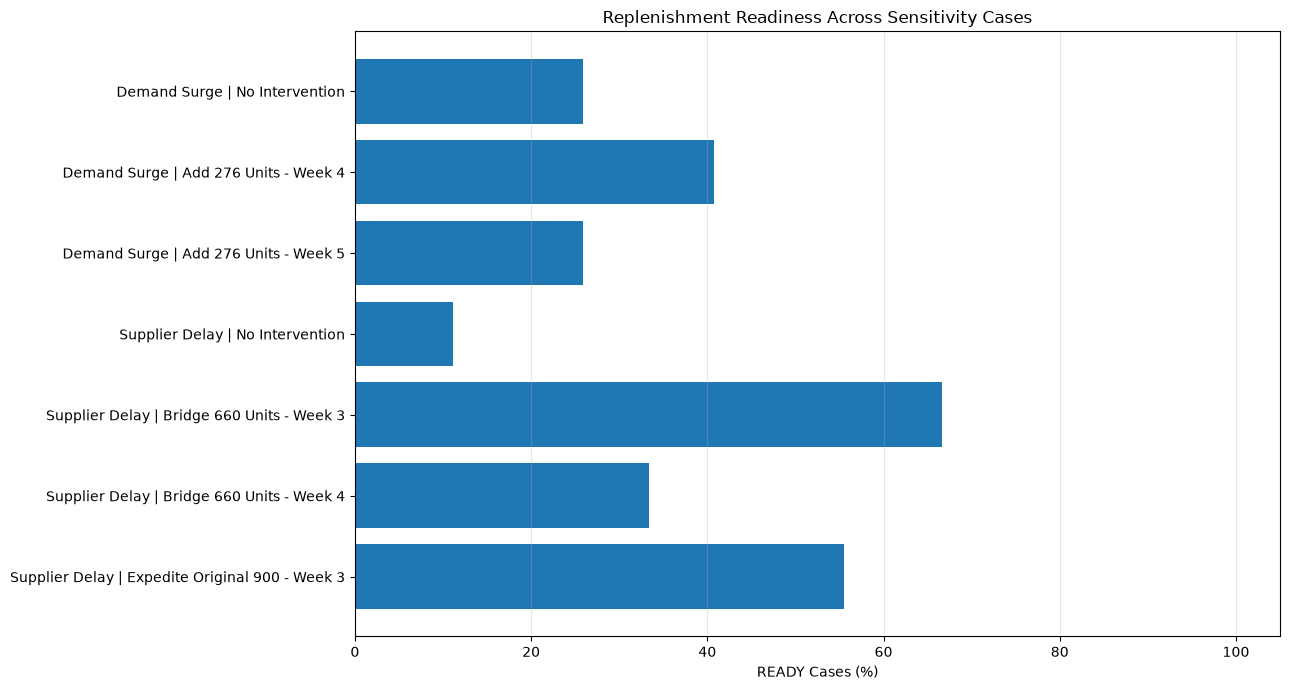

Saved: sensitivity_readiness_by_action.png


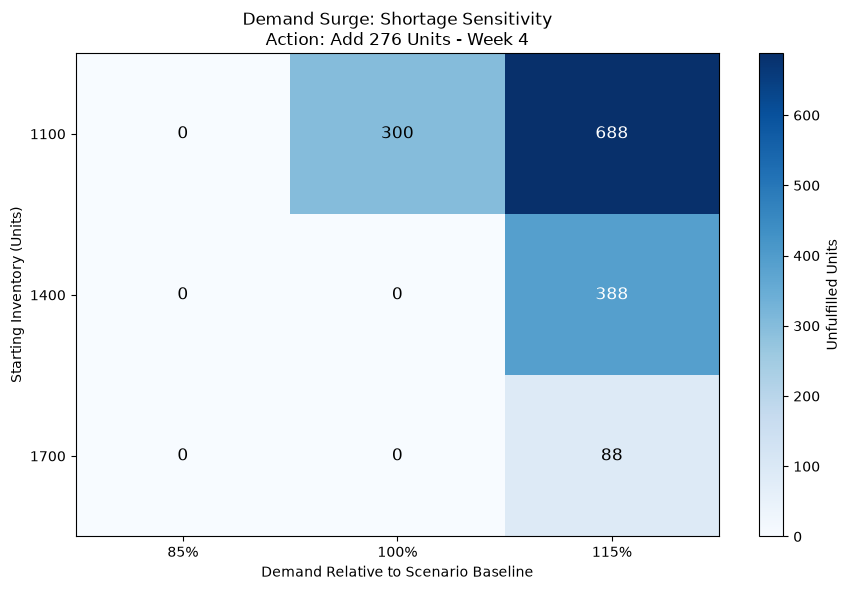

Saved: sensitivity_shortage_heatmap_demand_surge.png


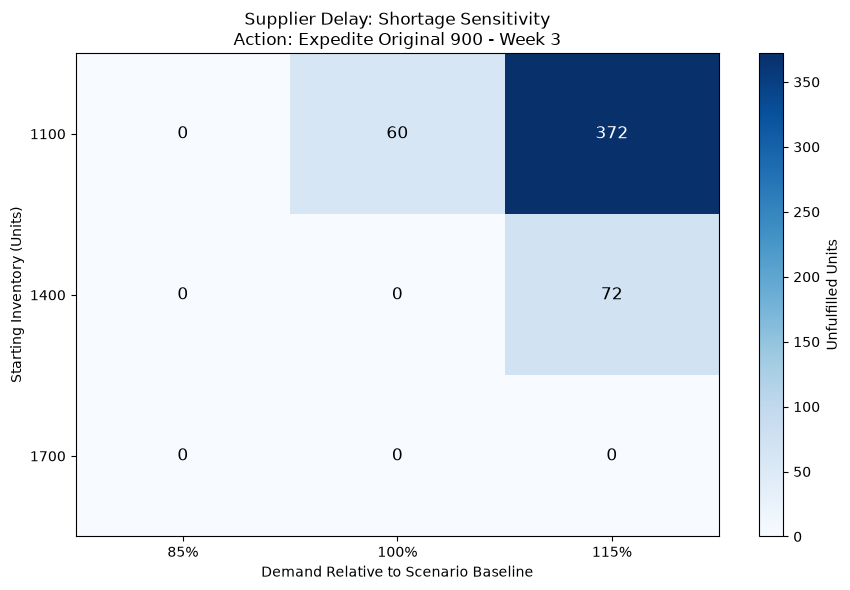

Saved: sensitivity_shortage_heatmap_supplier_delay.png

===== ECONOMIC SENSITIVITY SUMMARY =====


,Shortage_Penalty_USD,No_Action_Exposure,Reference_Exposure,Scenario,Modeled_Exposure_Reduction_USD
0,25.0,10115.74,11016.63,Demand Surge,-900.89
1,75.0,30347.22,25425.89,Demand Surge,4921.33
2,125.0,50578.70,39835.15,Demand Surge,10743.56
3,25.0,12819.44,5230.56,Supplier Delay,7588.89
4,75.0,38458.33,10691.67,Supplier Delay,27766.67
5,125.0,64097.22,16152.78,Supplier Delay,47944.44


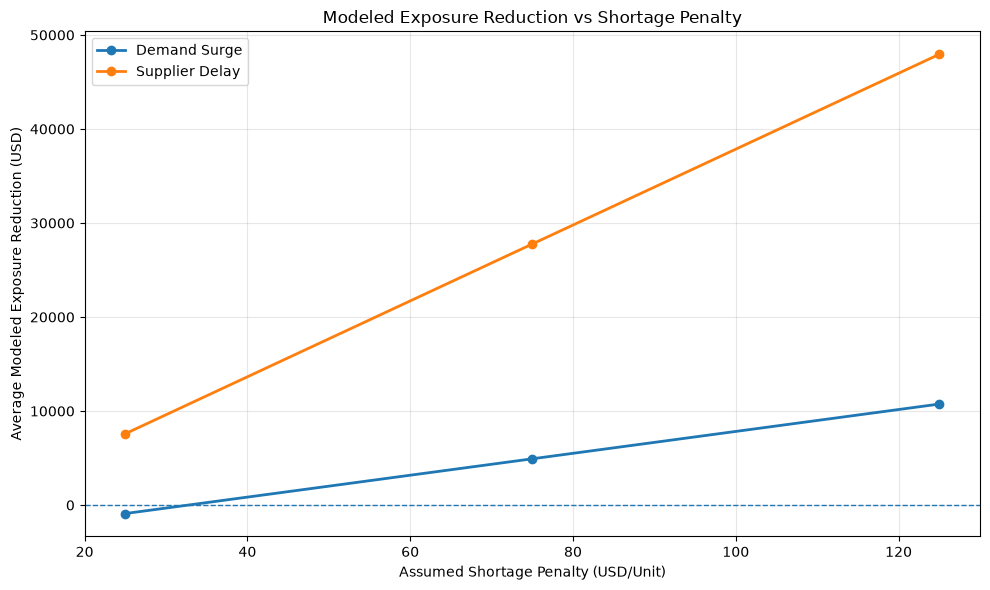

Saved: sensitivity_economic_tradeoffs.png

===== VISUALIZATION VALIDATION =====
Decision tie-breaking refined: PASS
162 cases reconciled: PASS
90 cases with READY options: PASS
Two shortage heatmaps created: PASS
Four PNG visualizations saved: PASS

===== STEP 5 COMPLETE =====


In [6]:
# STEP 5: VISUALIZE INVENTORY SENSITIVITY AND ROBUSTNESS


from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# PART 1: IMPROVE TIE-BREAKING FOR READY ACTIONS
# ------------------------------------------------------------

# First minimize modeled exposure.
# If costs are identical, prefer No Intervention.
# Then minimize future commitments and extra receipts.

ready_candidates = decision_data[
    decision_data["Readiness_Status"] == "READY"
].copy()

ready_candidates["No_Action_Penalty"] = (
    ready_candidates["Action"] != "No Intervention"
).astype(int)

lowest_ready = (
    ready_candidates
    .sort_values([
        "Case_ID",
        "Total_Exposure_USD",
        "No_Action_Penalty",
        "Outstanding_Units",
        "Received_Extra_Units",
        "Action"
    ])
    .drop_duplicates("Case_ID")
    [
        [
            "Case_ID",
            "Action",
            "Total_Exposure_USD",
            "Total_Shortage"
        ]
    ]
    .rename(columns={
        "Action": "Lowest_Ready_Action",
        "Total_Exposure_USD":
            "Lowest_Ready_Exposure_USD",
        "Total_Shortage": "Lowest_Ready_Shortage"
    })
)

# Replace previous case-level recommendations.

case_results = case_results.drop(
    columns=[
        "Lowest_Ready_Action",
        "Lowest_Ready_Exposure_USD",
        "Lowest_Ready_Shortage",
        "Ready_Available",
        "Ready_Exposure_Gap_vs_No_Action_USD"
    ],
    errors="ignore"
)

case_results = case_results.merge(
    lowest_ready,
    on="Case_ID",
    how="left",
    validate="one_to_one"
)

case_results["Ready_Available"] = (
    case_results["Lowest_Ready_Exposure_USD"].notna()
)

case_results["Ready_Exposure_Gap_vs_No_Action_USD"] = (
    case_results["Lowest_Ready_Exposure_USD"]
    - case_results["No_Action_Exposure_USD"]
)

case_results["Lowest_Ready_Action"] = (
    case_results["Lowest_Ready_Action"]
    .fillna("NO READY OPTION")
)

# Recalculate decision frequency.

action_frequency = (
    case_results
    .groupby(
        ["Scenario", "Lowest_Ready_Action"]
    )
    .size()
    .reset_index(name="Cases")
)

action_frequency["Share_of_Cases_Pct"] = (
    action_frequency["Cases"] / 81 * 100
)

print("===== CORRECTED DECISION FREQUENCY =====")

display(
    action_frequency.sort_values(
        ["Scenario", "Cases"],
        ascending=[True, False]
    ).round(2)
)


# ------------------------------------------------------------
# PART 2: CHART INTERVENTION READINESS RATES
# ------------------------------------------------------------

chart_data = robustness_scorecard.copy()

chart_data["Label"] = (
    chart_data["Scenario"]
    + " | "
    + chart_data["Action"]
)

fig, ax = plt.subplots(figsize=(13, 7))

ax.barh(
    chart_data["Label"],
    chart_data["Ready_Rate_Pct"]
)

ax.set_title(
    "Replenishment Readiness Across Sensitivity Cases"
)

ax.set_xlabel("READY Cases (%)")
ax.set_xlim(0, 105)

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

readiness_path = (
    figures_dir / "sensitivity_readiness_by_action.png"
)

fig.savefig(
    readiness_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", readiness_path.name)


# ------------------------------------------------------------
# PART 3: CREATE TWO SHORTAGE SENSITIVITY HEATMAPS
# ------------------------------------------------------------

heatmap_paths = []

for scenario_name, reference_action in reference_actions.items():

    # Hold delivery timing and penalty at reference
    # assumptions. Vary demand and starting inventory.

    heatmap_data = decision_data[
        (decision_data["Scenario"] == scenario_name)
        &
        (decision_data["Action"] == reference_action)
        &
        (decision_data["Arrival_Week_Adjustment"] == 0)
        &
        (decision_data["Shortage_Penalty_USD"] == 75.0)
    ].copy()

    assert len(heatmap_data) == 9

    heatmap_table = (
        heatmap_data
        .pivot(
            index="Starting_Inventory",
            columns="Demand_Adjustment",
            values="Total_Shortage"
        )
        .sort_index()
        .sort_index(axis=1)
    )

    assert heatmap_table.shape == (3, 3)

    values = heatmap_table.to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(9, 6))

    image = ax.imshow(
        values,
        cmap="Blues",
        aspect="auto"
    )

    ax.set_xticks(range(len(heatmap_table.columns)))

    ax.set_xticklabels([
        f"{value:.0%}"
        for value in heatmap_table.columns
    ])

    ax.set_yticks(range(len(heatmap_table.index)))

    ax.set_yticklabels(
        heatmap_table.index.astype(str)
    )

    ax.set_xlabel(
        "Demand Relative to Scenario Baseline"
    )

    ax.set_ylabel("Starting Inventory (Units)")

    ax.set_title(
        f"{scenario_name}: Shortage Sensitivity\n"
        f"Action: {reference_action}"
    )

    midpoint = (
        float(values.min()) + float(values.max())
    ) / 2

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):

            value = int(values[i, j])

            ax.text(
                j, i, f"{value:,}",
                ha="center",
                va="center",
                color=(
                    "white"
                    if value > midpoint
                    else "black"
                ),
                fontsize=12
            )

    fig.colorbar(
        image,
        ax=ax,
        label="Unfulfilled Units"
    )

    fig.tight_layout()

    filename = (
        "sensitivity_shortage_heatmap_"
        + scenario_name.lower().replace(" ", "_")
        + ".png"
    )

    output_path = figures_dir / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    heatmap_paths.append(output_path)

    print("Saved:", filename)


# ------------------------------------------------------------
# PART 4: COMPARE ECONOMIC BENEFITS BY SHORTAGE PENALTY
# ------------------------------------------------------------

economic_records = []

for scenario_name, reference_action in reference_actions.items():

    scenario_data = penalty_tradeoffs[
        penalty_tradeoffs["Scenario"] == scenario_name
    ]

    baseline_costs = (
        scenario_data[
            scenario_data["Action"] == "No Intervention"
        ][
            [
                "Shortage_Penalty_USD",
                "Average_Exposure_USD"
            ]
        ]
        .rename(columns={
            "Average_Exposure_USD": "No_Action_Exposure"
        })
    )

    reference_costs = (
        scenario_data[
            scenario_data["Action"] == reference_action
        ][
            [
                "Shortage_Penalty_USD",
                "Average_Exposure_USD"
            ]
        ]
        .rename(columns={
            "Average_Exposure_USD": "Reference_Exposure"
        })
    )

    comparison = baseline_costs.merge(
        reference_costs,
        on="Shortage_Penalty_USD",
        validate="one_to_one"
    )

    comparison["Scenario"] = scenario_name

    comparison["Modeled_Exposure_Reduction_USD"] = (
        comparison["No_Action_Exposure"]
        - comparison["Reference_Exposure"]
    )

    economic_records.append(comparison)

economic_sensitivity = pd.concat(
    economic_records,
    ignore_index=True
)

print("\n===== ECONOMIC SENSITIVITY SUMMARY =====")

display(economic_sensitivity.round(2))

fig, ax = plt.subplots(figsize=(10, 6))

for scenario_name, group in economic_sensitivity.groupby(
    "Scenario"
):

    group = group.sort_values("Shortage_Penalty_USD")

    ax.plot(
        group["Shortage_Penalty_USD"],
        group["Modeled_Exposure_Reduction_USD"],
        marker="o",
        linewidth=2,
        label=scenario_name
    )

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title(
    "Modeled Exposure Reduction vs Shortage Penalty"
)

ax.set_xlabel("Assumed Shortage Penalty (USD/Unit)")
ax.set_ylabel("Average Modeled Exposure Reduction (USD)")

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()

economic_path = (
    figures_dir / "sensitivity_economic_tradeoffs.png"
)

fig.savefig(
    economic_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved:", economic_path.name)


# ------------------------------------------------------------
# PART 5: VALIDATE REVISED RESULTS AND FIGURES
# ------------------------------------------------------------

assert len(case_results) == 162

assert (
    action_frequency.groupby("Scenario")["Cases"].sum()
    == 81
).all()

assert (
    case_results["Ready_Available"].sum()
    == 90
)

# No READY candidate should have a shortage.
assert (
    case_results.loc[
        case_results["Ready_Available"],
        "Lowest_Ready_Shortage"
    ] == 0
).all()

assert len(economic_sensitivity) == 6

chart_paths = [
    readiness_path,
    *heatmap_paths,
    economic_path
]

assert len(chart_paths) == 4

for path in chart_paths:
    assert path.is_file()
    assert path.stat().st_size > 0

print("\n===== VISUALIZATION VALIDATION =====")

print("Decision tie-breaking refined: PASS")
print("162 cases reconciled: PASS")
print("90 cases with READY options: PASS")
print("Two shortage heatmaps created: PASS")
print("Four PNG visualizations saved: PASS")

print("\n===== STEP 5 COMPLETE =====")


In [7]:
# STEP 6A: EXPORT INVENTORY SENSITIVITY ANALYSIS RESULTS

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: DEFINE EXPORT DIRECTORY
# ------------------------------------------------------------

sensitivity_output_dir = (
    project_root / "data" / "processed"
)

sensitivity_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("===== SENSITIVITY EXPORT DIRECTORY =====")
print(sensitivity_output_dir)


# ------------------------------------------------------------
# PART 2: DEFINE EIGHT ANALYTICAL EXPORTS
# ------------------------------------------------------------

sensitivity_exports = {

    "sensitivity_intervention_evaluations.csv":
        robustness_results,

    "sensitivity_weekly_inventory.csv":
        sensitivity_weekly,

    "sensitivity_action_robustness.csv":
        robustness_scorecard,

    "sensitivity_decision_cases.csv":
        case_results,

    "sensitivity_decision_coverage.csv":
        decision_coverage,

    "sensitivity_action_frequency.csv":
        action_frequency,

    "sensitivity_shortage_penalty.csv":
        penalty_tradeoffs,

    "sensitivity_economic_tradeoffs.csv":
        economic_sensitivity
}

expected_rows = {

    "sensitivity_intervention_evaluations.csv": 567,

    "sensitivity_weekly_inventory.csv": 2268,

    "sensitivity_action_robustness.csv": 7,

    "sensitivity_decision_cases.csv": 162,

    "sensitivity_decision_coverage.csv": 2,

    "sensitivity_action_frequency.csv": 7,

    "sensitivity_shortage_penalty.csv": 21,

    "sensitivity_economic_tradeoffs.csv": 6
}


# ------------------------------------------------------------
# PART 3: VALIDATE KEY EXPERIMENT RELATIONSHIPS
# ------------------------------------------------------------

assert (
    robustness_results[
        ["Case_ID", "Action"]
    ].duplicated().sum() == 0
)

assert (
    sensitivity_weekly[
        ["Case_ID", "Action", "Week"]
    ].duplicated().sum() == 0
)

assert case_results["Case_ID"].is_unique

assert (
    decision_coverage["Cases_With_Ready_Action"]
    .sum() == 90
)

assert (
    decision_coverage["No_Ready_Option_Cases"]
    .sum() == 72
)

assert (
    action_frequency["Cases"].sum() == 162
)

print("\n===== EXPERIMENT RELATIONSHIP VALIDATION =====")

print("Unique intervention evaluations: PASS")
print("Unique weekly simulation records: PASS")
print("Unique operating-case decisions: PASS")
print("90 cases with READY options: PASS")
print("72 cases without READY options: PASS")


# ------------------------------------------------------------
# PART 4: EXPORT AND RELOAD DATASETS
# ------------------------------------------------------------

export_records = []

for filename, dataframe in sensitivity_exports.items():

    output_path = (
        sensitivity_output_dir / filename
    )

    assert len(dataframe) == expected_rows[filename]

    dataframe.to_csv(
        output_path,
        index=False,
        date_format="%Y-%m-%d"
    )

    # Reload exported CSV for verification.
    verified = pd.read_csv(output_path)

    assert len(verified) == len(dataframe)

    assert (
        verified.columns.tolist()
        == dataframe.columns.tolist()
    )

    assert output_path.stat().st_size > 0

    export_records.append({
        "File": filename,
        "Rows": len(verified),
        "Columns": len(verified.columns),
        "Status": "PASS"
    })

    print(
        f"Exported: {filename} "
        f"({len(verified)} rows)"
    )


# ------------------------------------------------------------
# PART 5: PRESERVE NO-READY-OPTION INFORMATION
# ------------------------------------------------------------

decision_export = pd.read_csv(
    sensitivity_output_dir
    / "sensitivity_decision_cases.csv"
)

no_ready_cases = decision_export[
    decision_export["Lowest_Ready_Action"]
    == "NO READY OPTION"
]

assert len(no_ready_cases) == 72

# These missing values are intentional:
# no READY intervention exists for those cases.
assert no_ready_cases[
    "Lowest_Ready_Exposure_USD"
].isna().all()

print("\n===== DECISION INTEGRITY VALIDATION =====")

print("No-ready cases preserved:", len(no_ready_cases))
print("Undefined READY costs remain missing: PASS")


# ------------------------------------------------------------
# PART 6: VALIDATE SAVED VISUALIZATIONS
# ------------------------------------------------------------

figure_files = [
    "sensitivity_readiness_by_action.png",
    "sensitivity_shortage_heatmap_demand_surge.png",
    "sensitivity_shortage_heatmap_supplier_delay.png",
    "sensitivity_economic_tradeoffs.png"
]

for filename in figure_files:

    figure_path = (
        project_root / "reports" / "figures" / filename
    )

    assert figure_path.is_file(), (
        f"Missing figure: {filename}"
    )

    assert figure_path.stat().st_size > 0

print("\n===== SAVED FIGURE VALIDATION =====")

for filename in figure_files:
    print("Verified:", filename)


# ------------------------------------------------------------
# PART 7: FINAL EXPORT VALIDATION
# ------------------------------------------------------------

sensitivity_export_report = pd.DataFrame(
    export_records
)

print("\n===== SENSITIVITY EXPORT REPORT =====")

display(sensitivity_export_report)

assert len(sensitivity_export_report) == 8

assert (
    sensitivity_export_report["Status"] == "PASS"
).all()

assert len(figure_files) == 4

print("\n===== FINAL VALIDATION =====")

print("Sensitivity CSV exports: 8")
print("Saved sensitivity charts: 4")
print("Operating cases: 162")
print("Intervention evaluations: 567")
print("Weekly simulation records: 2268")
print("All validation checks: PASS")

print("\n===== STEP 6A COMPLETE =====")


===== SENSITIVITY EXPORT DIRECTORY =====
/Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/data/processed

===== EXPERIMENT RELATIONSHIP VALIDATION =====
Unique intervention evaluations: PASS
Unique weekly simulation records: PASS
Unique operating-case decisions: PASS
90 cases with READY options: PASS
72 cases without READY options: PASS
Exported: sensitivity_intervention_evaluations.csv (567 rows)
Exported: sensitivity_weekly_inventory.csv (2268 rows)
Exported: sensitivity_action_robustness.csv (7 rows)
Exported: sensitivity_decision_cases.csv (162 rows)
Exported: sensitivity_decision_coverage.csv (2 rows)
Exported: sensitivity_action_frequency.csv (7 rows)
Exported: sensitivity_shortage_penalty.csv (21 rows)
Exported: sensitivity_economic_tradeoffs.csv (6 rows)

===== DECISION INTEGRITY VALIDATION =====
No-ready cases preserved: 72
Undefined READY costs remain missing: PASS

===== SAVED FIGURE VALIDATION =====
Verified: sensitivity_readiness_by_action.

,File,Rows,Columns,Status
0,sensitivity_intervention_evaluations.csv,567,32,PASS
1,sensitivity_weekly_inventory.csv,2268,12,PASS
2,sensitivity_action_robustness.csv,7,16,PASS
3,sensitivity_decision_cases.csv,162,24,PASS
4,sensitivity_decision_coverage.csv,2,9,PASS
5,sensitivity_action_frequency.csv,7,4,PASS
6,sensitivity_shortage_penalty.csv,21,10,PASS
7,sensitivity_economic_tradeoffs.csv,6,5,PASS



===== FINAL VALIDATION =====
Sensitivity CSV exports: 8
Saved sensitivity charts: 4
Operating cases: 162
Intervention evaluations: 567
Weekly simulation records: 2268
All validation checks: PASS

===== STEP 6A COMPLETE =====


In [8]:
# STEP 6B: INTEGRATE SENSITIVITY RESULTS INTO DUCKDB

from pathlib import Path
import pandas as pd
import duckdb

# ------------------------------------------------------------
# PART 1: CONNECT TO PERSISTENT DATABASE
# ------------------------------------------------------------

database_path = (
    project_root
    / "data"
    / "warehouse"
    / "demand_intelligence.duckdb"
)

assert database_path.is_file(), "Database not found."

print("===== SENSITIVITY DATABASE CONNECTION =====")
print(database_path)

# ------------------------------------------------------------
# PART 2: DEFINE SENSITIVITY DATASETS
# ------------------------------------------------------------

sensitivity_specs = {
    "sensitivity_intervention_evaluations.csv": (
        567,
        "Case x Action",
        "Matched intervention evaluations",
        "Robustness analysis"
    ),
    "sensitivity_weekly_inventory.csv": (
        2268,
        "Case x Action x Week",
        "Weekly inventory sensitivity results",
        "Inventory simulation"
    ),
    "sensitivity_action_robustness.csv": (
        7,
        "Scenario x Action",
        "Replenishment robustness scorecard",
        "Decision evaluation"
    ),
    "sensitivity_decision_cases.csv": (
        162,
        "Operating Case",
        "Selected actions and readiness availability",
        "Decision comparison"
    ),
    "sensitivity_decision_coverage.csv": (
        2,
        "Scenario",
        "Availability of READY interventions",
        "Decision coverage"
    ),
    "sensitivity_action_frequency.csv": (
        7,
        "Scenario x Selected Action",
        "Frequency of selected decisions",
        "Decision analysis"
    ),
    "sensitivity_shortage_penalty.csv": (
        21,
        "Scenario x Penalty x Action",
        "Shortage penalty sensitivity",
        "Economic analysis"
    ),
    "sensitivity_economic_tradeoffs.csv": (
        6,
        "Scenario x Penalty",
        "Modeled exposure reductions",
        "Economic analysis"
    )
}

# ------------------------------------------------------------
# PART 3: DEFINE SQL REPORTING VIEWS
# ------------------------------------------------------------

sensitivity_views = {
    "v_sensitivity_intervention_evaluations": (
        "sensitivity_intervention_evaluations", 567
    ),
    "v_sensitivity_action_robustness": (
        "sensitivity_action_robustness", 7
    ),
    "v_sensitivity_decision_cases": (
        "sensitivity_decision_cases", 162
    ),
    "v_sensitivity_decision_coverage": (
        "sensitivity_decision_coverage", 2
    ),
    "v_sensitivity_economic_tradeoffs": (
        "sensitivity_economic_tradeoffs", 6
    )
}

# ------------------------------------------------------------
# PART 4: OPEN CONNECTION AND TRANSACTION
# ------------------------------------------------------------

con = duckdb.connect(str(database_path))
transaction_open = False

try:

    con.execute("BEGIN TRANSACTION").fetchall()
    transaction_open = True

    con.execute(
        "CREATE SCHEMA IF NOT EXISTS sensitivity"
    ).fetchall()

    load_records = []

    # --------------------------------------------------------
    # PART 5: LOAD ALL EIGHT DATASETS
    # --------------------------------------------------------

    for filename, spec in sensitivity_specs.items():

        expected_rows, grain, meaning, role = spec

        file_path = processed_dir / filename

        assert file_path.is_file(), (
            f"Missing sensitivity file: {filename}"
        )

        df = pd.read_csv(file_path)

        assert len(df) == expected_rows

        table_name = Path(filename).stem
        assert table_name.isidentifier()

        # Preserve missing values as SQL NULLs.
        con.register("incoming_sensitivity", df)

        try:

            con.execute(
                f"""
                CREATE OR REPLACE TABLE
                    sensitivity.{table_name}
                AS
                SELECT * FROM incoming_sensitivity
                """
            ).fetchall()

        finally:

            con.unregister("incoming_sensitivity")

        sql_rows = con.execute(
            f"""
            SELECT COUNT(*)
            FROM sensitivity.{table_name}
            """
        ).fetchone()[0]

        assert sql_rows == expected_rows

        # ----------------------------------------------------
        # PART 6: UPDATE ARCHITECTURE METADATA
        # ----------------------------------------------------

        con.execute(
            """
            DELETE FROM metadata.architecture_catalog
            WHERE File_Name = ?
            """,
            [filename]
        ).fetchall()

        con.execute(
            """
            INSERT INTO metadata.architecture_catalog
            (
                File_Name,
                Source_Module,
                Grain,
                Business_Meaning,
                Analytical_Role
            )
            VALUES (?, ?, ?, ?, ?)
            """,
            [
                filename,
                "Inventory Sensitivity Analysis",
                grain,
                meaning,
                role
            ]
        ).fetchall()

        # ----------------------------------------------------
        # PART 7: UPDATE DATA QUALITY METADATA
        # ----------------------------------------------------

        missing_cells = int(df.isna().sum().sum())
        duplicate_rows = int(df.duplicated().sum())

        if "Forecast_Week" in df.columns:

            dates = pd.to_datetime(
                df["Forecast_Week"],
                errors="raise"
            )

            start_date = str(dates.min().date())
            end_date = str(dates.max().date())

        else:

            start_date = "N/A"
            end_date = "N/A"

        con.execute(
            """
            DELETE FROM metadata.data_quality_report
            WHERE File_Name = ?
            """,
            [filename]
        ).fetchall()

        con.execute(
            """
            INSERT INTO metadata.data_quality_report
            (
                File_Name,
                Source_Module,
                Rows,
                Columns,
                Missing_Cells,
                Duplicate_Rows,
                Start_Date,
                End_Date,
                Row_Check
            )
            VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
            """,
            [
                filename,
                "Inventory Sensitivity Analysis",
                len(df),
                len(df.columns),
                missing_cells,
                duplicate_rows,
                start_date,
                end_date,
                "PASS"
            ]
        ).fetchall()

        load_records.append({
            "Table": f"sensitivity.{table_name}",
            "CSV_Rows": len(df),
            "SQL_Rows": sql_rows,
            "Status": "PASS"
        })

        print(
            f"Loaded: sensitivity.{table_name} "
            f"({sql_rows} rows)"
        )

    # --------------------------------------------------------
    # PART 8: CREATE FIVE SQL REPORTING VIEWS
    # --------------------------------------------------------

    print("\n===== CREATING SENSITIVITY VIEWS =====")

    for view_name, (table_name, expected) in (
        sensitivity_views.items()
    ):

        assert view_name.isidentifier()
        assert table_name.isidentifier()

        con.execute(
            f"""
            CREATE OR REPLACE VIEW
                reporting.{view_name}
            AS
            SELECT *
            FROM sensitivity.{table_name}
            """
        ).fetchall()

        actual_rows = con.execute(
            f"""
            SELECT COUNT(*)
            FROM reporting.{view_name}
            """
        ).fetchone()[0]

        assert actual_rows == expected

        print(
            f"Validated: {view_name} "
            f"({actual_rows} rows)"
        )

    # --------------------------------------------------------
    # PART 9: VALIDATE DATABASE STRUCTURE
    # --------------------------------------------------------

    schema_rows = con.execute(
        """
        SELECT
            table_schema,
            COUNT(*) AS Table_Count

        FROM information_schema.tables

        WHERE table_schema IN (
            'demand',
            'ecommerce',
            'retail',
            'intent',
            'inventory',
            'sensitivity',
            'metadata'
        )

        AND table_type = 'BASE TABLE'

        GROUP BY table_schema
        ORDER BY table_schema
        """
    ).fetchall()

    schema_summary = pd.DataFrame(
        schema_rows,
        columns=["Schema", "Tables"]
    )

    print("\n===== EXPANDED DATABASE STRUCTURE =====")

    display(schema_summary)

    expected_counts = {
        "demand": 8,
        "ecommerce": 4,
        "intent": 2,
        "inventory": 8,
        "metadata": 3,
        "retail": 7,
        "sensitivity": 8
    }

    assert dict(schema_rows) == expected_counts

    total_tables = int(
        schema_summary["Tables"].sum()
    )

    assert total_tables == 40

    # --------------------------------------------------------
    # PART 10: VALIDATE VIEWS AND METADATA
    # --------------------------------------------------------

    total_views = con.execute(
        """
        SELECT COUNT(*)
        FROM information_schema.views
        WHERE table_schema = 'reporting'
        """
    ).fetchone()[0]

    assert total_views == 16

    metadata_counts = con.execute(
        """
        SELECT
            (SELECT COUNT(*)
             FROM metadata.architecture_catalog),

            (SELECT COUNT(*)
             FROM metadata.data_quality_report)
        """
    ).fetchone()

    assert metadata_counts == (37, 37)

    # --------------------------------------------------------
    # PART 11: VALIDATE NO-READY CASES
    # --------------------------------------------------------

    no_ready_count = con.execute(
        """
        SELECT COUNT(*)
        FROM sensitivity.sensitivity_decision_cases

        WHERE Lowest_Ready_Action = 'NO READY OPTION'
          AND Lowest_Ready_Exposure_USD IS NULL
        """
    ).fetchone()[0]

    assert no_ready_count == 72

    # --------------------------------------------------------
    # PART 12: FINAL REPORT
    # --------------------------------------------------------

    load_report = pd.DataFrame(load_records)

    print("\n===== SENSITIVITY TABLE LOAD REPORT =====")

    display(load_report)

    assert len(load_report) == 8
    assert (load_report["Status"] == "PASS").all()

    con.execute("COMMIT").fetchall()
    transaction_open = False

    print("\n===== FINAL DATABASE VALIDATION =====")

    print("Persistent SQL tables:", total_tables)
    print("Reporting views:", total_views)
    print("Architecture catalog entries:", metadata_counts[0])
    print("Data quality catalog entries:", metadata_counts[1])
    print("No-ready cases preserved:", no_ready_count)
    print("Sensitivity table reconciliation: PASS")
    print("Reporting view reconciliation: PASS")

    print("\n===== STEP 6B COMPLETE =====")

except Exception:

    if transaction_open:
        con.execute("ROLLBACK").fetchall()

    raise

finally:

    con.close()
    print("\nDatabase connection closed safely.")


===== SENSITIVITY DATABASE CONNECTION =====
/Users/sidkulkarni/Desktop/supply-chain-portfolio/hardware-demand-sensing-planner/data/warehouse/demand_intelligence.duckdb
Loaded: sensitivity.sensitivity_intervention_evaluations (567 rows)
Loaded: sensitivity.sensitivity_weekly_inventory (2268 rows)
Loaded: sensitivity.sensitivity_action_robustness (7 rows)
Loaded: sensitivity.sensitivity_decision_cases (162 rows)
Loaded: sensitivity.sensitivity_decision_coverage (2 rows)
Loaded: sensitivity.sensitivity_action_frequency (7 rows)
Loaded: sensitivity.sensitivity_shortage_penalty (21 rows)
Loaded: sensitivity.sensitivity_economic_tradeoffs (6 rows)

===== CREATING SENSITIVITY VIEWS =====
Validated: v_sensitivity_intervention_evaluations (567 rows)
Validated: v_sensitivity_action_robustness (7 rows)
Validated: v_sensitivity_decision_cases (162 rows)
Validated: v_sensitivity_decision_coverage (2 rows)
Validated: v_sensitivity_economic_tradeoffs (6 rows)

===== EXPANDED DATABASE STRUCTURE =====


,Schema,Tables
0,demand,8
1,ecommerce,4
2,intent,2
3,inventory,8
4,metadata,3
5,retail,7
6,sensitivity,8



===== SENSITIVITY TABLE LOAD REPORT =====


,Table,CSV_Rows,SQL_Rows,Status
0,sensitivity.sensitivity_intervention_evaluations,567,567,PASS
1,sensitivity.sensitivity_weekly_inventory,2268,2268,PASS
2,sensitivity.sensitivity_action_robustness,7,7,PASS
3,sensitivity.sensitivity_decision_cases,162,162,PASS
4,sensitivity.sensitivity_decision_coverage,2,2,PASS
5,sensitivity.sensitivity_action_frequency,7,7,PASS
6,sensitivity.sensitivity_shortage_penalty,21,21,PASS
7,sensitivity.sensitivity_economic_tradeoffs,6,6,PASS



===== FINAL DATABASE VALIDATION =====
Persistent SQL tables: 40
Reporting views: 16
Architecture catalog entries: 37
Data quality catalog entries: 37
No-ready cases preserved: 72
Sensitivity table reconciliation: PASS
Reporting view reconciliation: PASS

===== STEP 6B COMPLETE =====

Database connection closed safely.



# Inventory Sensitivity Analysis — Final Findings

## 1. Research Objective

Evaluate the robustness of hypothetical inventory replenishment decisions when demand, starting inventory, supplier delivery timing, and shortage costs change.

Extend the original inventory simulation beyond a single fixed set of assumptions.

## 2. Analytical Inputs

Sources:
- Historical four-week AirPods demand forecast
- Inventory scenario definitions
- Original replenishment intervention results
- Hypothetical economic and readiness assumptions

Historical forecast origin: December 29, 2019

Original forecast: 515 units per week.

All inventory, supplier, and economic parameters are hypothetical.

## 3. Sensitivity Experiment Design

Tested four dimensions:

- Demand adjustment: -15%, baseline, +15%
- Starting inventory: 1,100, 1,400, 1,700 units
- Original shipment arrival adjustment: -1, 0, +1 weeks
- Shortage penalty: $25, $75, $125 per unit

Experiment scale:
- 2 risk scenarios
- 81 parameter combinations per scenario
- 162 operating cases
- 7 replenishment action definitions
- 567 intervention evaluations
- 2,268 weekly inventory simulation records

Physical operating conditions were tested across 27 distinct combinations per risk scenario, each repeated at three shortage-penalty levels.

This is a deterministic sensitivity analysis, not a probability-weighted Monte Carlo simulation.

## 4. Replenishment Robustness Results

Percentage of selected parameter combinations classified as READY:

| Scenario | Action | READY Rate |
|---|---|---:|
| Demand Surge | No Intervention | 25.93% |
| Demand Surge | Add 276 Units — Week 4 | 40.74% |
| Demand Surge | Add 276 Units — Week 5 | 25.93% |
| Supplier Delay | No Intervention | 11.11% |
| Supplier Delay | Bridge 660 Units — Week 3 | 66.67% |
| Supplier Delay | Bridge 660 Units — Week 4 | 33.33% |
| Supplier Delay | Expedite Original 900 — Week 3 | 55.56% |

The original recovery actions were effective under reference assumptions but did not consistently prevent shortages across the sensitivity grid.

These readiness rates are not real-world success probabilities.

## 5. Decision Coverage

Demand Surge:
- 33 of 81 cases had at least one READY intervention
- 48 cases had no READY intervention
- Overall READY option coverage: 40.74%

Supplier Delay:
- 57 of 81 cases had at least one READY intervention
- 24 cases had no READY intervention
- Overall READY option coverage: 70.37%

Across both risk scenarios:
- 90 cases had at least one READY option
- 72 cases had no READY option

Cases with no qualifying intervention were preserved explicitly rather than assigned artificial zero-cost solutions.

## 6. Lowest-Exposure READY Decisions

Demand Surge:
- No Intervention: 21 cases
- Add 276 Units in Week 4: 12 cases
- No READY Option: 48 cases

Supplier Delay:
- Expedite Original 900 to Week 3: 36 cases
- Bridge 660 Units in Week 3: 12 cases
- No Intervention: 9 cases
- No READY Option: 24 cases

Selection prioritized the lowest modeled exposure among actions meeting readiness criteria.

When modeled costs tied, the selection logic preferred no unnecessary intervention and fewer outstanding inventory commitments.

These are ex-post decisions assuming operating conditions are known, not a deployable replenishment policy.

## 7. Demand and Inventory Sensitivity

Demand-surge reference intervention:

With 1,100 starting units and demand 15% above the original surge scenario, adding 276 units in Week 4 still left 688 units unfulfilled.

Supplier-delay reference intervention:

With 1,100 starting units and demand 15% higher than the original supplier-delay scenario, expediting the original shipment to Week 3 still left 372 units unfulfilled.

These findings demonstrate the limitations of fixed replenishment quantities under more severe operating conditions.

## 8. Economic Sensitivity

Evaluated hypothetical shortage penalties of:
- $25 per unfulfilled unit
- $75 per unfulfilled unit
- $125 per unfulfilled unit

Additional assumptions included:
- $12 emergency supply premium per unit received
- $500 emergency shipment delivery fee
- $2,500 original shipment expediting fee

Higher shortage penalties generally increased the modeled financial attractiveness of interventions that prevented more shortages.

Economic comparisons exclude full procurement, inventory holding, supplier capacity, and post-horizon costs.

No realized savings are claimed.

## 9. Technical Deliverables

Implemented:
- Reusable four-week inventory simulator
- Parameter-grid sensitivity evaluation
- Matched no-intervention comparisons
- Replenishment robustness scorecard
- Service-constrained decision selection
- Economic sensitivity analysis
- Explicit handling of cases without READY options

Exported:
- 8 sensitivity analysis CSV files
- 4 sensitivity visualizations

Integrated into DuckDB:
- 8 sensitivity tables
- 5 sensitivity reporting views

Current analytical database:
- 40 persistent SQL tables
- 16 SQL reporting views
- 37 architecture catalog entries
- 37 data-quality catalog entries

All newly loaded table row counts and reporting view counts passed validation.

## 10. Key Business Implications

1. Replenishment recommendations should be stress-tested against uncertainty rather than evaluated under only one demand forecast.

2. Supplier timing and starting inventory materially affect modeled fulfillment performance.

3. The most economically attractive intervention is not always the most consistent at achieving service targets.

4. Some operating conditions require additional recovery options beyond the existing intervention menu.

5. Decision-support systems should explicitly communicate when no available option meets operational requirements.

## 11. Limitations

- All operating scenarios and cost assumptions are hypothetical.
- Historical product demand comes from a limited 2019 dataset.
- The sensitivity grid is deterministic and not probability-weighted.
- A READY status represents a modeled inventory-fulfillment criterion only.
- Some emergency supply costs beyond the planning horizon are excluded.
- No actual supplier capacity or replenishment feasibility was verified.
- Scenario recommendations assume operating conditions are known.
- The current database construction is distributed across notebooks and must be consolidated for reproducibility.

## 12. Next Development Phase

- Consolidate the DuckDB data-build pipeline
- Validate full end-to-end reproducibility
- Assess Helium 10 historical market-signal feasibility
- Integrate defensible external demand signals where possible
- Develop the Power BI executive dashboard
- Polish final visualizations and analytical narratives
- Prepare the GitHub README and website portfolio case study
